# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import DFC21DSEDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Show images and masks

Total number of patches: 60


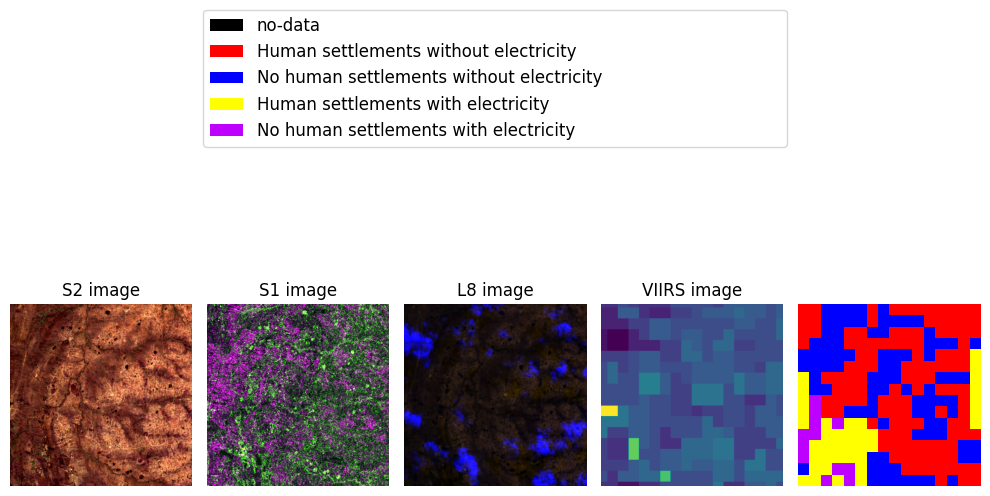

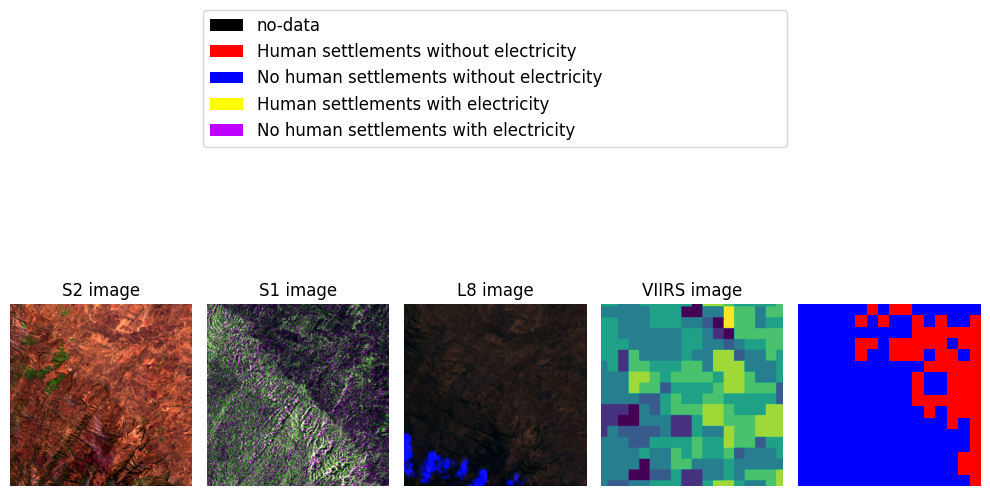

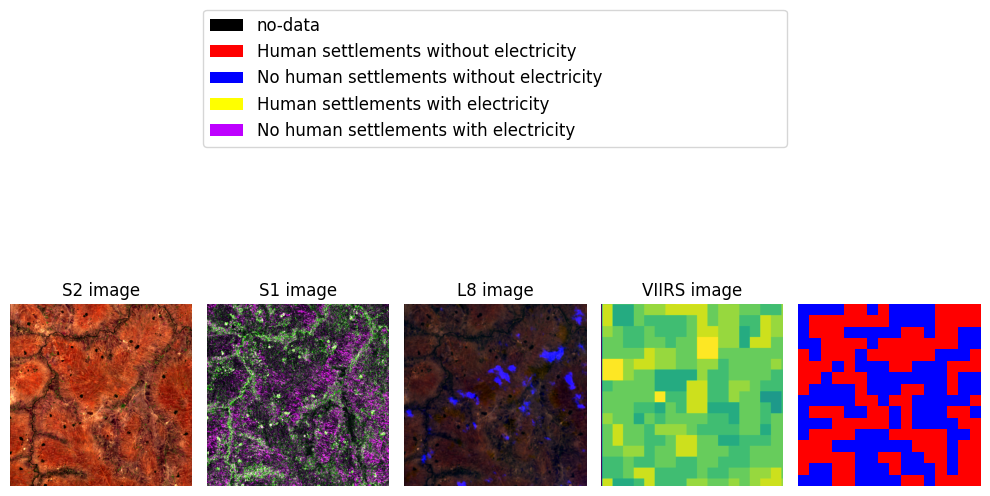

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/dfc21_dse/Train",
    "selection": "rgb",
    "time_series": False,
    "imagery": "all"
}
dataset = DFC21DSEDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(20);
dataset.show_image(30);
dataset.show_image(50);

In [146]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.0
Human settlements without electricity,6318.0
No human settlements without electricity,8155.0
Human settlements with electricity,676.0
No human settlements with electricity,211.0


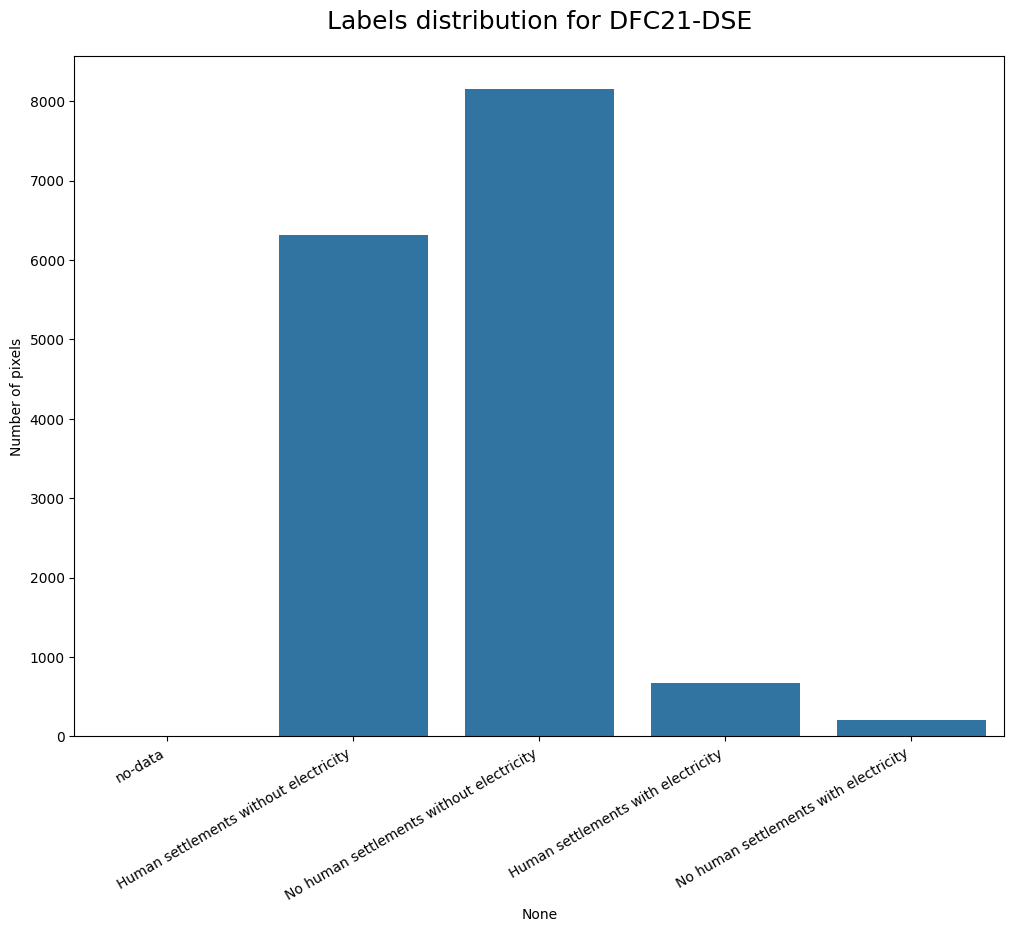

In [147]:
dataset.data_distribution_barchart();

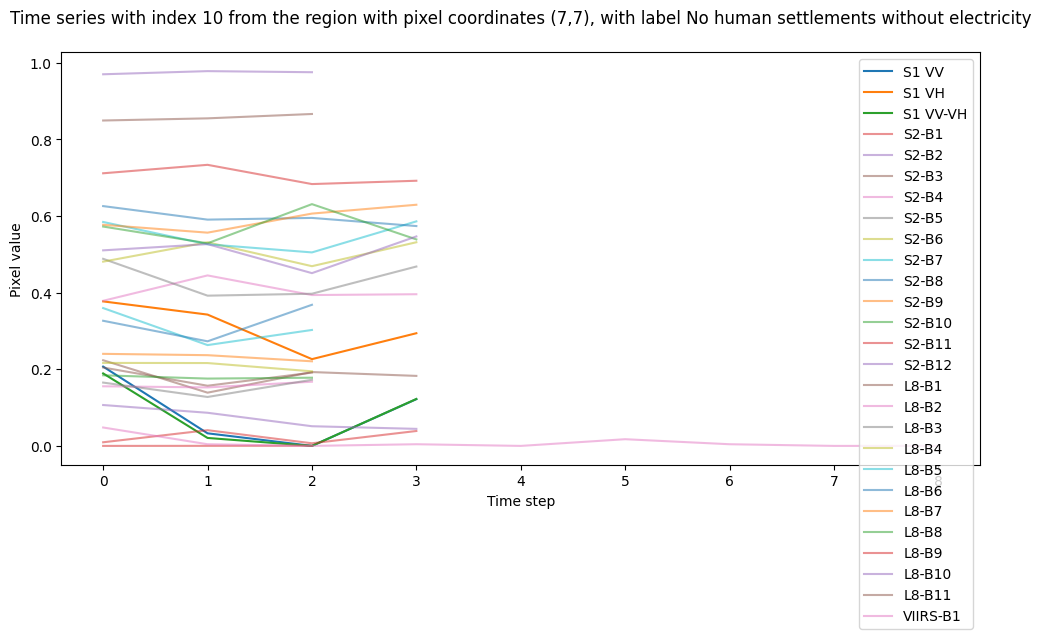

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/dfc21_dse/Train",
    "selection": "all",
    "time_series": True,
    "imagery": "all"
}
dataset = DFC21DSEDataset(dataset_config)
fig = dataset.show_timeseries(index=10, longitude=7, latitude=7)

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/dfc21_dse/Train",
    "selection": "rgb",
    "time_series": False,
    "imagery": "s2",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = DFC21DSEDataset(train_dataset_config)
len(train_dataset)

60

## Create the model

In [195]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/dfc21_dse"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [196]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-12-24 10:29:42,348 INFO Starting training.
training: 100%|██████████| 8/8 [00:23<00:00,  2.99s/it]
2025-12-24 10:30:06,355 INFO epoch: 1, time: 24, loss:  0.71055
testing on train set: 100%|██████████| 8/8 [00:11<00:00,  1.47s/it]
2025-12-24 10:30:20,154 INFO IOU:0.09087129643964223, IOU mean:0.08661114250868285, IOU per Class:[0.         0.15529993 0.25486226 0.02167587 0.00121765]
training: 100%|██████████| 8/8 [00:10<00:00,  1.36s/it]
2025-12-24 10:30:31,033 INFO epoch: 2, time: 11, loss:  0.68475
testing on train set: 100%|██████████| 8/8 [00:10<00:00,  1.33s/it]
2025-12-24 10:30:41,695 INFO IOU:0.15984355256506258, IOU mean:0.0784233223409421, IOU per Class:[0.         0.15529989 0.2093611  0.02745562 0.        ]
training: 100%|██████████| 8/8 [00:11<00:00,  1.38s/it]
2025-12-24 10:30:52,728 INFO epoch: 3, time: 11, loss:  0.65689
testing on train set: 100%|██████████| 8/8 [00:11<00:00,  1.38s/it]
2025-12-24 10:31:03,808 INFO IOU:0.19357960314599712, IOU mean:0.08231416756312

## Predictions

2025-12-24 10:49:57,150 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/dfc21_dse/checkpoint.pth.tar
2025-12-24 10:49:57,453 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/dfc21_dse/checkpoint.pth.tar at epoch 21


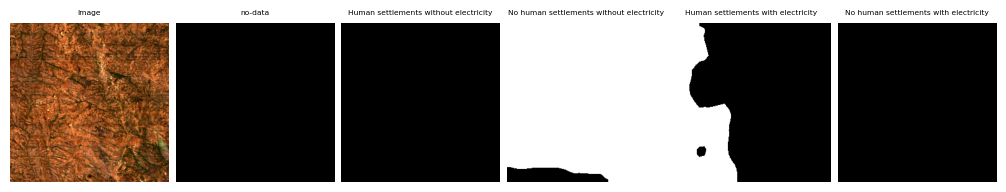

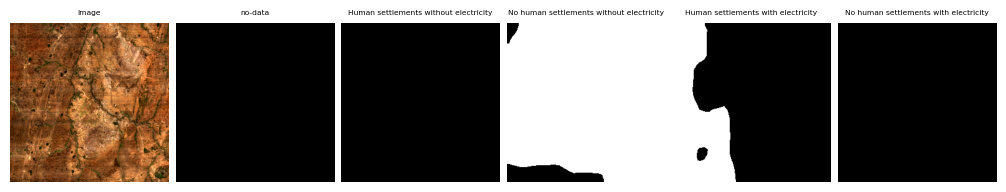

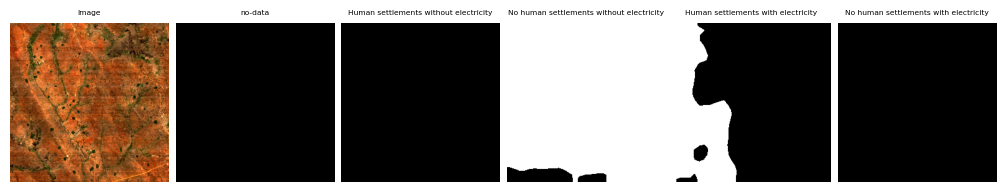

In [ ]:
model_path = "/home/dragik/data/FAIR_EO/experiments/dfc21_dse/checkpoint.pth.tar"
labels = ["no-data","Human settlements without electricity","No human settlements without electricity","Human settlements with electricity","No human settlements with electricity"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4.5})

imageb1 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile1/L2A_20200811_B04.tif')
imageb2 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile1/L2A_20200811_B03.tif')
imageb3 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile1/L2A_20200811_B02.tif')
image = np.dstack((imageb1, imageb2, imageb3))
# normalize image for better visualization
p1 = np.percentile(image, 1, axis=(1, 2), keepdims=True)
p99 = np.percentile(image, 99.5, axis=(1, 2), keepdims=True)

image = np.clip(image, p1, p99)
image = (image - p1) / (p99 - p1 + 1e-8)
fig = model.predict_masks(image, labels, transform)

imageb1 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile10/L2A_20200811_B04.tif')
imageb2 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile10/L2A_20200811_B03.tif')
imageb3 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile10/L2A_20200811_B02.tif')
image = np.dstack((imageb1, imageb2, imageb3))
# normalize image
p1 = np.percentile(image, 1, axis=(1, 2), keepdims=True)
p99 = np.percentile(image, 99.5, axis=(1, 2), keepdims=True)

image = np.clip(image, p1, p99)
image = (image - p1) / (p99 - p1 + 1e-8)
fig = model.predict_masks(image, labels, transform)

imageb1 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile15/L2A_20200811_B04.tif')
imageb2 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile15/L2A_20200811_B03.tif')
imageb3 = image_loader('/home/dragik/data/FAIR_EO/dfc21_dse/Test/Tile15/L2A_20200811_B02.tif')
image = np.dstack((imageb1, imageb2, imageb3))
# normalize image
p1 = np.percentile(image, 1, axis=(1, 2), keepdims=True)
p99 = np.percentile(image, 99.5, axis=(1, 2), keepdims=True)

image = np.clip(image, p1, p99)
image = (image - p1) / (p99 - p1 + 1e-8)
fig = model.predict_masks(image, labels, transform)